Explained variance by the 2 components: 33.60%


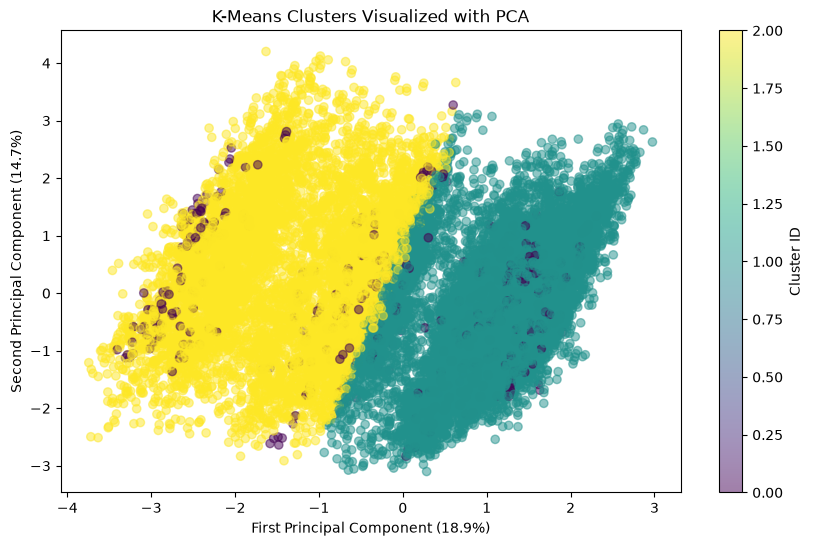

In [1]:
import sys
sys.path.append('../src')
from preprocessing import load_and_preprocess

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Load Data (Features only, we ignore the targets for unsupervised learning)
X, _, _ = load_and_preprocess()

# 2. Scaling is CRITICAL for PCA and K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. PCA for Dimensionality Reduction (down to 2 components for 2D plotting)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance by the 2 components: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 4. K-Means Clustering (let's find 3 natural profiles)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 5. Visualize the Clusters using the PCA dimensions
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', alpha=0.5)
plt.title('K-Means Clusters Visualized with PCA')
plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.colorbar(scatter, label='Cluster ID')
plt.savefig('../figures/pca_kmeans_clusters.png') # Saving for MLLB report
plt.show()